# Relación entre ingreso y proporción de gasto en salud

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Integración con llaves verificadas
Se combinan las fuentes de las dos prácticas previas por entidad y año. La unión uno a uno
evita multiplicar registros. Se conserva un solo código y se trabaja con entidades ISO3.
[Salud](https://ourworldindata.org/grapher/total-healthcare-expenditure-gdp) ·
[PIB](https://ourworldindata.org/grapher/gdp-per-capita-worldbank).

In [2]:
salud = solo_paises(indicador("total-healthcare-expenditure-gdp", "current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct", "percentage_health"))
pib = indicador("gdp-per-capita-worldbank", "ny_gdp_pcap_pp_kd", "gdp")
unido = salud.merge(pib.drop(columns="code"), on=["entity", "year"], validate="one_to_one")
unido = unido.dropna(subset=["gdp", "percentage_health"])
print("Filas unidas:", len(unido), "Entidades:", unido.entity.nunique())
display(unido.head())

Filas unidas: 4406 Entidades: 186


,entity,code,year,percentage_health,gdp
0,Afghanistan,AFG,2002,9.443391,1774.3087
1,Afghanistan,AFG,2003,8.941258,1815.9282
2,Afghanistan,AFG,2004,9.808474,1776.9182
3,Afghanistan,AFG,2005,9.948289,1908.1147
4,Afghanistan,AFG,2006,10.622766,1929.7239


## 2. Correlación del panel y de un corte anual
El panel repite entidades a través del tiempo. Para evitar confundir esa repetición con
una muestra de países independientes, se informa también Pearson y Spearman solo para 2021.
La correlación no mide el efecto causal del ingreso sobre el gasto.

,comparacion,correlacion
0,Panel completo,0.1939
1,Corte 2021,0.2240
2,Corte 2021 (Spearman),0.3379


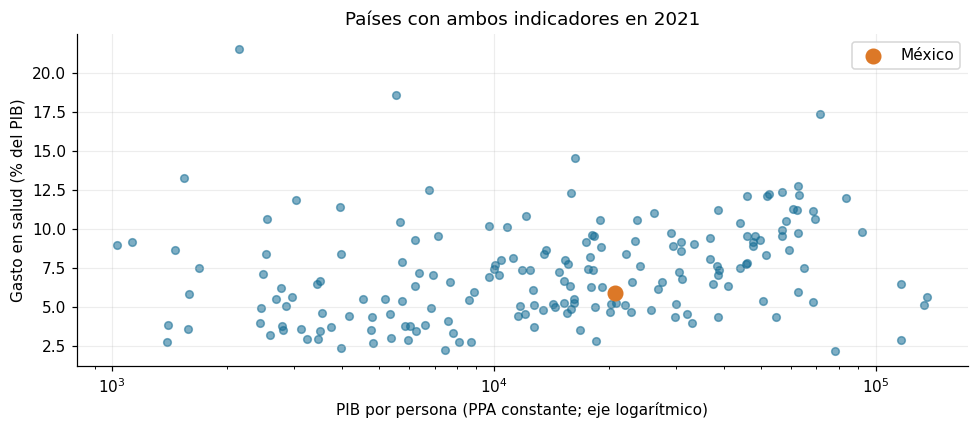

In [3]:
corte = unido.loc[unido.year.eq(2021)].copy()
r_panel = unido.gdp.corr(unido.percentage_health)
r_2021 = corte.gdp.corr(corte.percentage_health)
rho = corte.gdp.corr(corte.percentage_health, method="spearman")
display(pd.DataFrame({"comparacion": ["Panel completo", "Corte 2021", "Corte 2021 (Spearman)"],
                      "correlacion": [r_panel, r_2021, rho]}).round(4))
plt.scatter(corte.gdp, corte.percentage_health, alpha=.55, s=25)
mx = corte.loc[corte.entity.eq("Mexico")].iloc[0]
plt.scatter([mx.gdp], [mx.percentage_health], color="#dc7827", s=90, label="México")
plt.xscale("log")
plt.xlabel("PIB por persona (PPA constante; eje logarítmico)")
plt.ylabel("Gasto en salud (% del PIB)")
plt.title("Países con ambos indicadores en 2021")
plt.legend()
guardar_figura("06_salud_pib_corte")

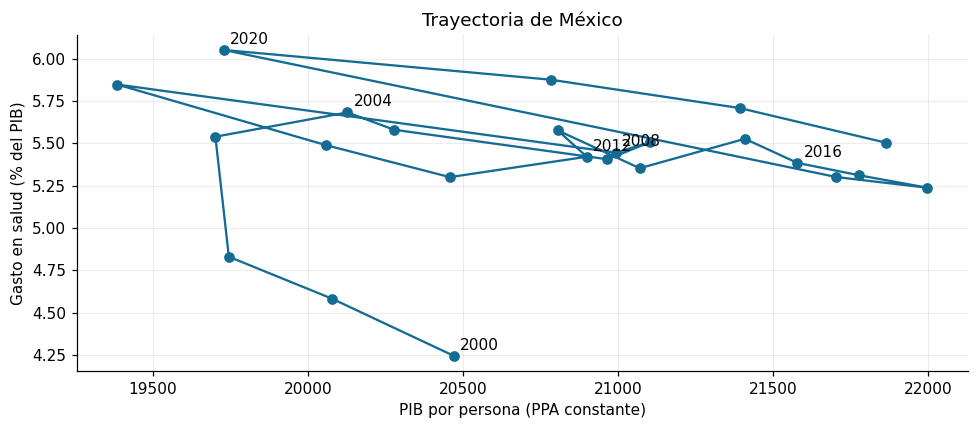

CSV guardado: U3_1_modelos_ml/data/processed/salud_pib_unidos.csv (4,406 filas)


**Resultado:** en 186 entidades de 2021, Pearson es **0.224** y Spearman **0.338**. En el panel completo Pearson es **0.194**.

In [4]:
mexico = unido.loc[unido.entity.eq("Mexico") & unido.year.between(2000, 2023)].sort_values("year")
plt.plot(mexico.gdp, mexico.percentage_health, "o-")
for fila in mexico.iloc[::4].itertuples():
    plt.annotate(str(fila.year), (fila.gdp, fila.percentage_health), xytext=(4, 4), textcoords="offset points")
plt.xlabel("PIB por persona (PPA constante)")
plt.ylabel("Gasto en salud (% del PIB)")
plt.title("Trayectoria de México")
guardar_figura("06_salud_pib_mexico")
guardar_tabla(unido, "salud_pib_unidos.csv")
display(Markdown(f"**Resultado:** en {len(corte)} entidades de 2021, Pearson es **{r_2021:.3f}** "
                 f"y Spearman **{rho:.3f}**. En el panel completo Pearson es **{r_panel:.3f}**."))

## 3. Respuestas
**¿Más ingreso implica mayor proporción de gasto?** La tabla cuantifica la asociación;
su dispersión muestra que no existe una relación exacta. Dos países con ingreso similar
pueden tener proporciones distintas. **¿Puede concluirse causalidad?** No: políticas,
estructura por edad, precios y cobertura no están controlados. **¿Por qué comparar el
mismo año?** Evita mezclar directamente niveles monetarios y condiciones de periodos distintos.
El eje logarítmico solo mejora la visualización: la correlación de Pearson mostrada usa el PIB original.